# Entanglement-capacity certificates: a short walkthrough

This notebook reads the result files written by `run_all.sh` and shows the main
numbers behind the paper. The first section also recomputes one certificate from
scratch so you can see the whole calculation in a few lines. Run `run_all.sh`
first if the `.json` files are missing.

In [1]:
import json
import numpy as np
from IPython.display import Image, display
import certlib as C

load = lambda name: json.load(open(name))
expA_rows = load('expA_rows.json')
expB = load('expB_sector.json')
expB2 = load('expB2_sector_scaling.json')
expC = load('expC_joint.json')
expDE = load('expDE.json')
expF = load('expF.json')
expG = load('expG_hubbard.json')
expH = load('expH_multiblock.json')
expI = load('expI_angle_budget.json')

## The rank certificate on one cut

For a product-initialised circuit with $g_C$ CNOT or CZ gates across cut $C$, the
output has Schmidt rank at most $2^{g_C}$ there, so

$$E^\star_{\mathcal A}-E_0 \ge \Delta\,[1-\Lambda_C(2^{g_C})].$$

Below is the central cut of the critical periodic TFIM at $n=6$.

In [2]:
n = 6
H = C.build_TFIM(n, h=1.0, periodic=True)
w, v = np.linalg.eigh(H)
E0, gap = w[0], w[1] - w[0]
sv = C.schmidt_vals(v[:, 0], n // 2, n)
print(f"E0 = {E0:.4f}, gap = {gap:.4f}")
for g in range(4):
    L = C.Lam(sv, 2 ** g)
    print(f"g = {g}:  Lambda_C(2^g) = {L:.4f}   floor = {gap * (1 - L):.2e}")

E0 = -7.7274, gap = 0.2633
g = 0:  Lambda_C(2^g) = 0.7712   floor = 6.02e-02
g = 1:  Lambda_C(2^g) = 0.9891   floor = 2.86e-03
g = 2:  Lambda_C(2^g) = 0.9999   floor = 1.78e-05
g = 3:  Lambda_C(2^g) = 1.0000   floor = 1.17e-16


## Symmetry sectors

When every gate and the initial state commute with the parity $P=\prod_i X_i$,
the relevant gap is the gap inside the parity sector. In the ordered phase this
is much larger than the global gap, which is set by the finite-size doublet.

In [3]:
for tag in ('ordered', 'critical', 'paramagnetic'):
    r = expB[tag]
    print(f"{tag:12s} global gap {r['gap_global']:.3e}   sector gap {r['gap_sector']:.4f}   "
          f"floor at g=0: global {r['floor_global'][0]:.1e}, sector {r['floor_sector'][0]:.2f}")
print()
for r in expB2['rows']:
    print(f"n = {r['n']:2d}: sector gap / global gap = {r['ratio']:.3g}")
print(f"growth rate: exp({expB2['slope']:.2f} n)")

ordered      global gap 1.456e-03   sector gap 2.2843   floor at g=0: global 7.0e-04, sector 1.10
critical     global gap 1.970e-01   sector gap 1.5607   floor at g=0: global 4.9e-02, sector 0.39
paramagnetic global gap 2.003e+00   sector gap 4.5686   floor at g=0: global 7.1e-02, sector 0.16

n =  6: sector gap / global gap = 360
n =  8: sector gap / global gap = 1.57e+03
n = 10: sector gap / global gap = 6.82e+03
n = 12: sector gap / global gap = 2.94e+04
growth rate: exp(0.73 n)


## The angle budget

Rank counting cannot see how strong an entangler is. A gate
$e^{-i\theta P\otimes Q}$ moves a state at most
$\tilde\theta=\min(|\theta|,\pi/2-|\theta|)$ in Fubini-Study distance from every
Schmidt-rank class, so several weak gates are only as useful as one gate of the
same total angle. On the four-qubit singlet test, with up to three gates on the
central bond, the best trained energies sit on the bound. On the critical
Ising chain the bound keeps certifying a floor at depths where the rank floor
vanishes.

In [4]:
for r in expI['I2']['rows']:
    print(f"p = {r['p']}  theta = {r['theta']:.2f}   trained {r['err']:.4f}   "
          f"angle budget {r['budget']:.4f}   triangle {r['triangle']:.4f}")
print()
for r in expI['I3']['rows']:
    print(f"TFIM n=8  p = {r['p']}  theta = {r['theta']:.3f}   trained {r['err']:.3f}   "
          f"angle budget {r['budget']:.1e}   rank {r['rank']:.1e}")

p = 1  theta = 0.05   trained 1.8003   angle budget 1.8003   triangle 1.7073
p = 1  theta = 0.10   trained 1.6027   angle budget 1.6027   triangle 1.3954
p = 1  theta = 0.15   trained 1.4090   angle budget 1.4090   triangle 1.0653
p = 1  theta = 0.25   trained 1.0411   angle budget 1.0411   triangle 0.3556
p = 2  theta = 0.05   trained 1.6027   angle budget 1.6027   triangle 1.3946
p = 2  theta = 0.10   trained 1.2212   angle budget 1.2212   triangle 0.7110
p = 2  theta = 0.15   trained 0.8707   angle budget 0.8707   triangle 0.0000
p = 2  theta = 0.25   trained 0.3171   angle budget 0.3171   triangle 0.0000
p = 3  theta = 0.05   trained 1.4090   angle budget 1.4090   triangle 1.0619
p = 3  theta = 0.10   trained 0.8707   angle budget 0.8707   triangle 0.0000
p = 3  theta = 0.15   trained 0.4333   angle budget 0.4333   triangle 0.0000
p = 3  theta = 0.25   trained 0.0050   angle budget 0.0050   triangle 0.0000

TFIM n=8  p = 1  theta = 0.020   trained 0.358   angle budget 3.7e-02   ran

## Allocation does not improve training

Water-filling minimises the certified floor at a fixed gate budget. Within each
instance we compare the arm with the lowest floor against the arm with the
highest floor and ask which one trained better.

In [5]:
ARMS = ['layer', 'wf_unc', 'wf_con', 'rand_con']
by = {(r['inst'], r['G'], r['arm']): r for r in expA_rows}
insts = sorted({r['inst'] for r in expA_rows})
for G in (8, 9, 11):
    agree = total = 0
    for i in insts:
        seen, arms = set(), []
        for a in ARMS:
            r = by.get((i, G, a))
            if r and tuple(r['alloc']) not in seen:
                seen.add(tuple(r['alloc']))
                arms.append((r['floor'], r['err']))
        lo = min(arms, key=lambda x: x[0]); hi = max(arms, key=lambda x: x[0])
        if lo[0] == hi[0]:
            continue
        total += 1
        agree += lo[1] < hi[1]
    print(f"G = {G:2d}: lowest-floor layout trained best in {agree}/{total} instances")

G =  8: lowest-floor layout trained best in 6/16 instances
G =  9: lowest-floor layout trained best in 5/16 instances
G = 11: lowest-floor layout trained best in 1/16 instances


In [6]:
for G in (5, 7, 8, 9, 11):
    f = [by[(i, G, a)]['floor'] for i in insts for a in ARMS if (i, G, a) in by]
    e = [by[(i, G, a)]['err'] for i in insts for a in ARMS if (i, G, a) in by]
    print(f"G = {G:2d}: median floor {np.median(f):.2e}, median trained error {np.median(e):.2e}, "
          f"ratio {np.median(e) / np.median(f):.0f}x")

G =  5: median floor 1.47e-02, median trained error 2.10e-01, ratio 14x
G =  7: median floor 1.97e-04, median trained error 6.41e-02, ratio 325x
G =  8: median floor 1.34e-04, median trained error 5.55e-02, ratio 414x
G =  9: median floor 7.10e-05, median trained error 5.32e-02, ratio 749x
G = 11: median floor 1.02e-05, median trained error 7.85e-02, ratio 7672x


## Joint multi-cut capacity

A circuit bounds the rank at every cut at once. The best floor that can be drawn
from all those ranks together lies between a multi-block Ky Fan bound (from
below) and the sum of the single-cut floors (from above); an MPS fit tightens
the upper end where it is available. Here is a two-Bell-pair example where the
multi-block bound beats every single cut, then the disordered ensemble at
budget 5.

In [7]:
bell = np.array([1, 0, 0, 1]) / np.sqrt(2)
psi = np.kron(bell, bell)
R = [1, 4, 1]
svs = C.cut_data(psi, 4)
print("single cuts:", [round(C.Lam(svs[k], R[k]), 3) for k in range(3)],
      " multi-block:", round(C.multiblock_capacity(psi, 4, R), 3))

for e in sorted((e for e in expH['ensemble'] if e['G'] == 5), key=lambda e: (e['inst'], e['arm'])):
    print(f"inst {e['inst']:2d} {e['arm']:6s} best rank-only floor in "
          f"[{e['floor_mb']:.2e}, {e['floor_max']:.2e}]  independent-cut {e['floor_indep']:.2e}  "
          f"trained {e['err']:.3f}")

single cuts: [0.5, 1.0, 0.5]  multi-block: 0.25
inst  0 layer  best rank-only floor in [3.33e-02, 3.50e-02]  independent-cut 2.71e-02  trained 0.152
inst  0 wf_unc best rank-only floor in [8.14e-03, 9.09e-03]  independent-cut 4.95e-03  trained 0.306
inst  1 layer  best rank-only floor in [1.49e-02, 1.77e-02]  independent-cut 1.32e-02  trained 0.125
inst  1 wf_unc best rank-only floor in [1.04e-02, 1.06e-02]  independent-cut 7.28e-03  trained 0.168
inst  2 layer  best rank-only floor in [2.81e-02, 3.93e-02]  independent-cut 2.81e-02  trained 0.086
inst  2 wf_unc best rank-only floor in [4.72e-03, 4.78e-03]  independent-cut 3.39e-03  trained 0.256
inst  3 layer  best rank-only floor in [4.51e-02, 5.53e-02]  independent-cut 3.46e-02  trained 0.234
inst  3 wf_unc best rank-only floor in [1.43e-02, 2.08e-02]  independent-cut 1.43e-02  trained 0.268
inst  4 layer  best rank-only floor in [4.09e-03, 5.29e-03]  independent-cut 4.09e-03  trained 0.065
inst  4 wf_unc best rank-only floor in [4.0

## Fermi-Hubbard orderings

Two qubit orderings of the same Hamiltonian share $E_0$ and the gap but place
the entanglement differently along the chain.

In [8]:
for k in ('interleaved', 'spin-sector'):
    r = expG[k]
    print(f"{k:12s} E0 = {r['E0']:.4f}  gap = {r['gap']:.4f}  bottleneck floor {r['peak']:.4f} at cut {r['peak_cut']}")
print("ground state particle number:", expG['number_check']['levels'][0]['N'])

interleaved  E0 = -4.4221  gap = 0.3585  bottleneck floor 0.1238 at cut 4
spin-sector  E0 = -4.4221  gap = 0.3585  bottleneck floor 0.0534 at cut 3
ground state particle number: 4.000000000000005


## Figures

These are the figures used in the paper, written by `make_figures.py`.

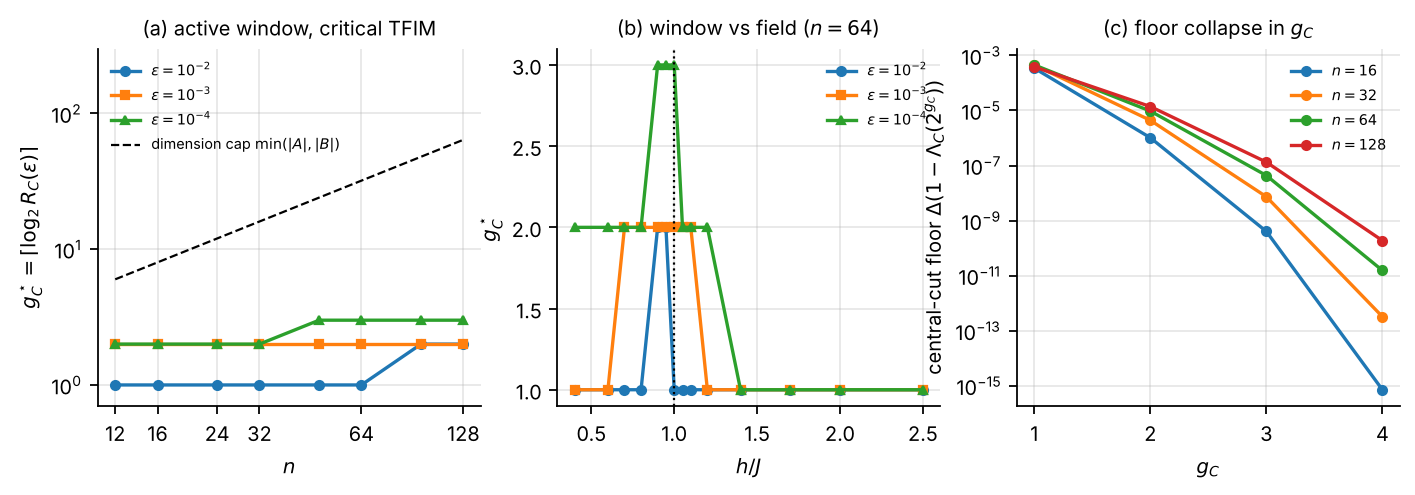

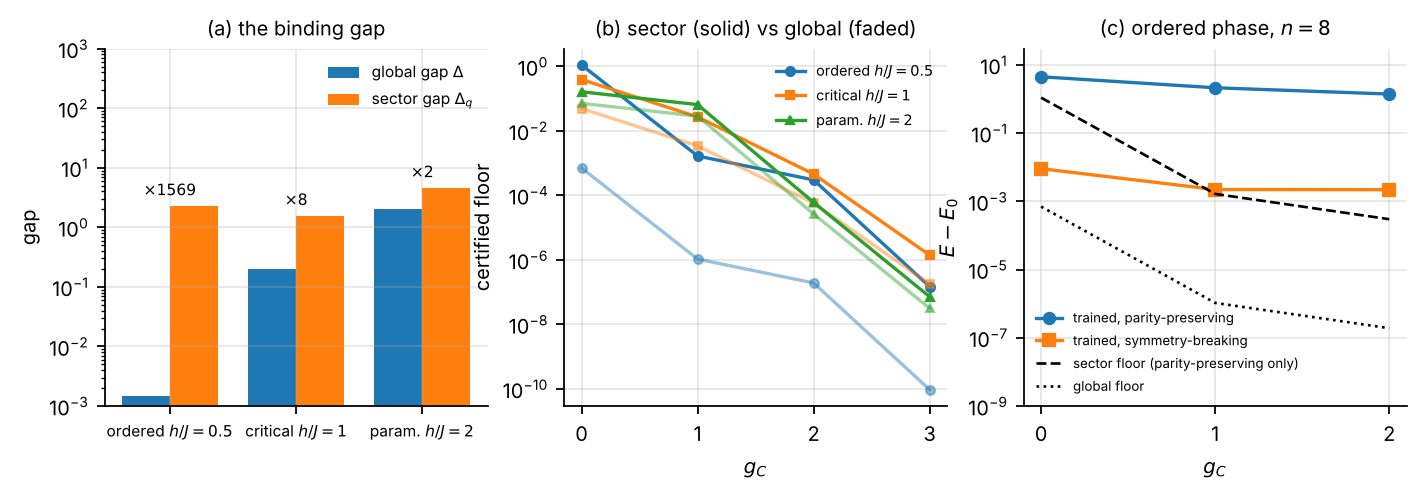

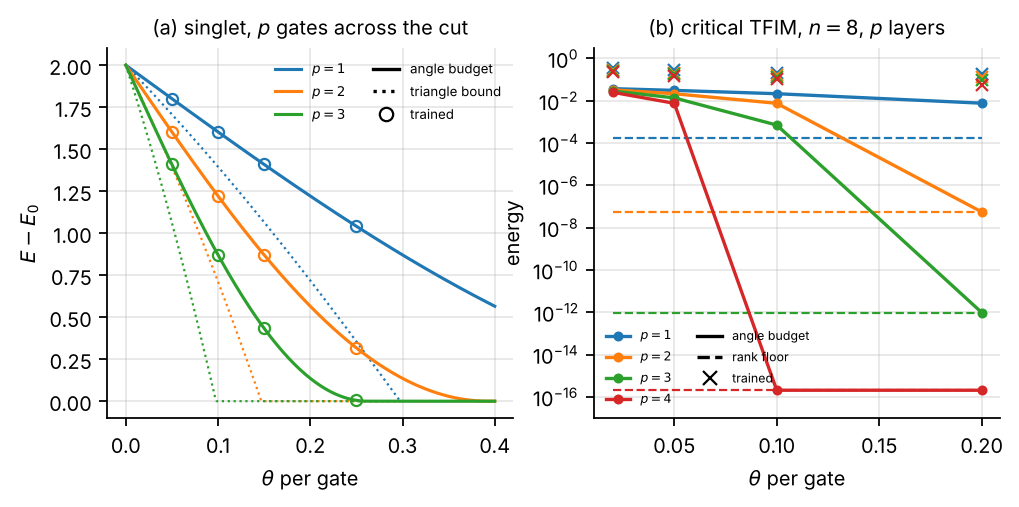

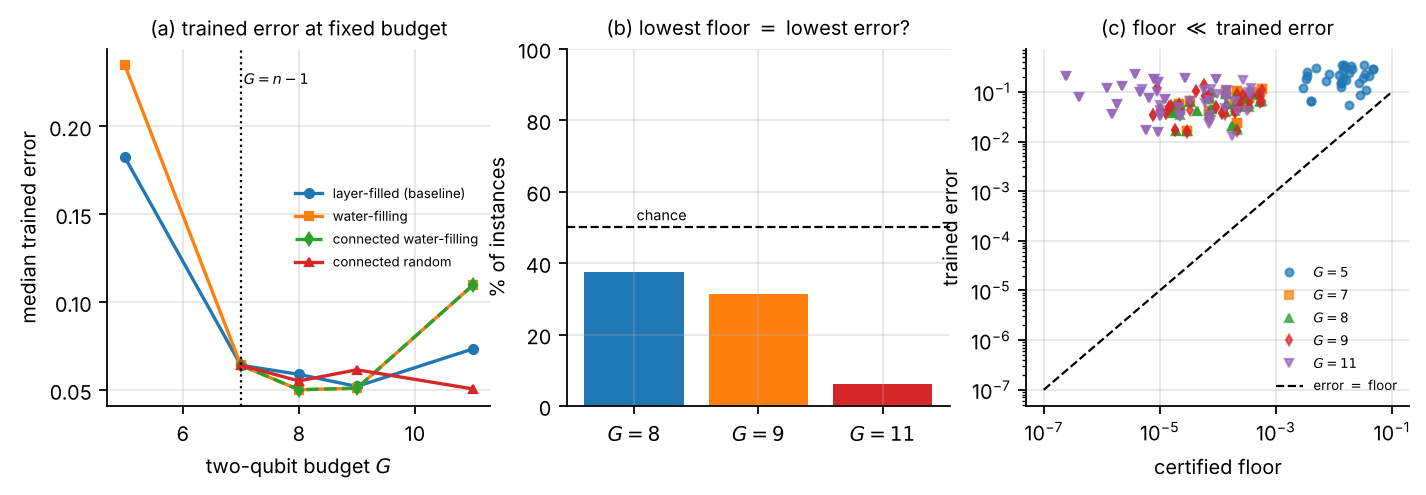

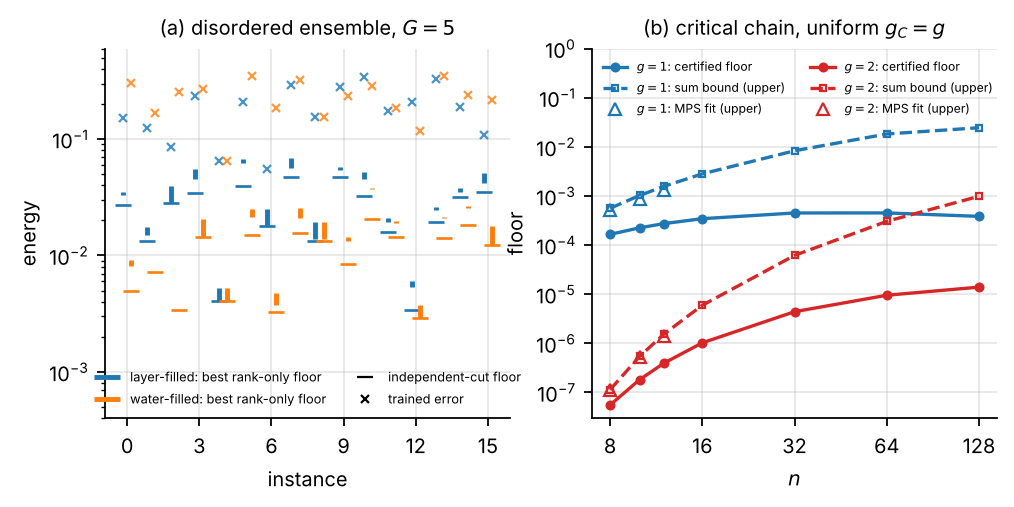

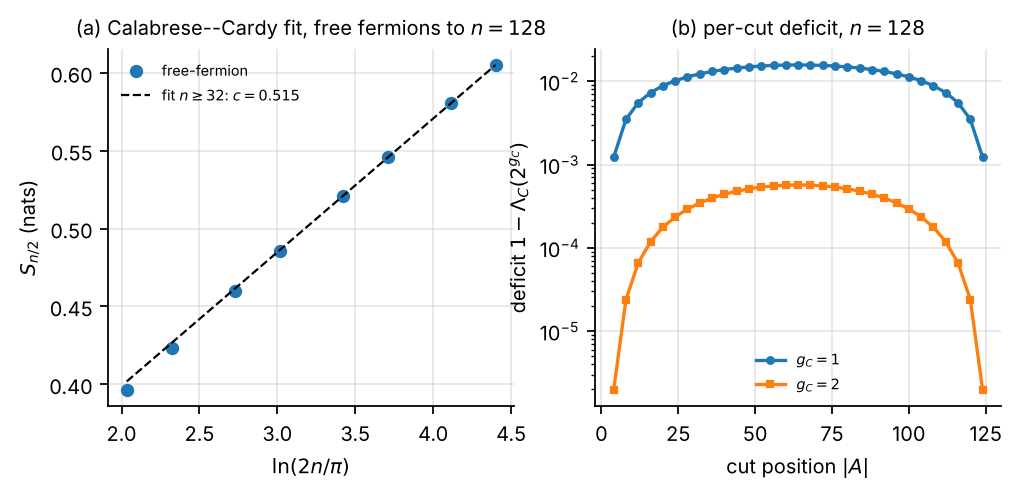

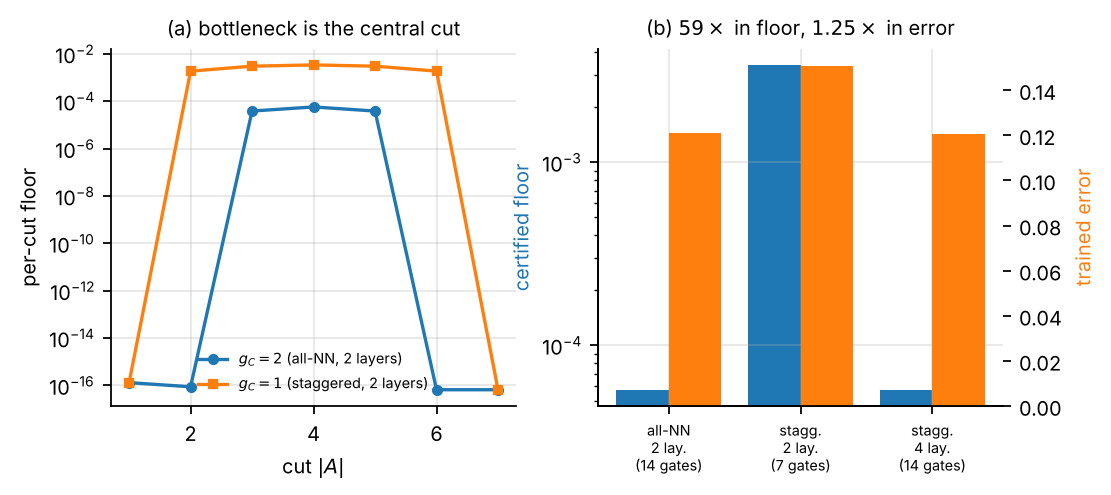

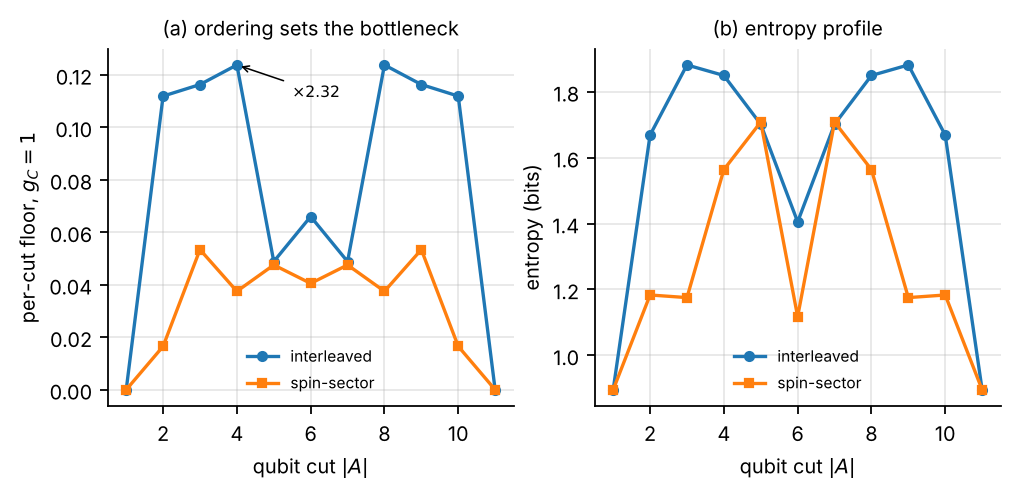

In [9]:
for name in ('window', 'sector', 'angle', 'allocation', 'joint', 'scaling', 'percut', 'hubbard'):
    display(Image(filename=f'figures/{name}.png'))